<a href="https://colab.research.google.com/github/neska1505/pharma-sales-analysis/blob/main/pharma_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib as mp

In [2]:
df_sales = pd.read_csv("salesdaily.csv")

In [3]:
df_sales

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.00,3.670,3.40,32.40,7.0,0.0,0.0,2.00,2014,1,248,Thursday
1,1/3/2014,8.00,4.000,4.40,50.60,16.0,0.0,20.0,4.00,2014,1,276,Friday
2,1/4/2014,2.00,1.000,6.50,61.85,10.0,0.0,9.0,1.00,2014,1,276,Saturday
3,1/5/2014,4.00,3.000,7.00,41.10,8.0,0.0,3.0,0.00,2014,1,276,Sunday
4,1/6/2014,5.00,1.000,4.50,21.70,16.0,2.0,6.0,2.00,2014,1,276,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday


In [4]:
atc_columns = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
total_sales = df_sales[atc_columns].sum().reset_index()
total_sales.columns = ['ATC Code Category', 'Total Sales Quantity']

display(total_sales.sort_values(by='Total Sales Quantity', ascending=False))

,ATC Code Category,Total Sales Quantity
3,N02BE,63005.402708
4,N05B,18645.737500
6,R03,11608.822917
0,M01AB,10600.937083
1,M01AE,8204.618646
2,N02BA,8172.209000
7,R06,6107.817500
5,N05C,1249.958333


In [5]:
df_sales['datum'] = pd.to_datetime(df_sales['datum'])
atc_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

def get_top_three_for_month(year, month):
    filtered = df_sales[(df_sales['datum'].dt.year == year) & (df_sales['datum'].dt.month == month)]
    totals = filtered[atc_cols].sum().sort_values(ascending=False).head(3)
    return totals

periods = [
    (2015, 1, "January 2015"),
    (2016, 7, "July 2016"),
    (2017, 9, "September 2017")
]

for year, month, label in periods:
    print(f"--- Top 3 Drug Categories for {label} ---")
    print(get_top_three_for_month(year, month))
    print()

--- Top 3 Drug Categories for January 2015 ---
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

--- Top 3 Drug Categories for July 2016 ---
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

--- Top 3 Drug Categories for September 2017 ---
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64



In [6]:
sales_2017 = df_sales[df_sales['datum'].dt.year == 2017]

total_sales_2017 = sales_2017[atc_cols].sum()


top_drug_2017 = total_sales_2017.idxmax()
top_sales_value = total_sales_2017.max()

print(f"The drug category that sold the most in 2017 is {top_drug_2017} with a total sales quantity of {top_sales_value:.2f}.")
print("\nFull sales breakdown for 2017:")
display(total_sales_2017.sort_values(ascending=False))

The drug category that sold the most in 2017 is N02BE with a total sales quantity of 9258.80.

Full sales breakdown for 2017:


,0
N02BE,9258.804833
N05B,2555.541667
R03,1893.614583
M01AB,1846.617083
M01AE,1387.298333
N02BA,1288.295833
R06,988.860000
N05C,180.333333


In [8]:
avg_daily_sales = df_sales[atc_cols].mean().sort_values(ascending=False)

top_category = avg_daily_sales.index[0]
top_val = avg_daily_sales.iloc[0]

print(f"The drug category with the highest average daily sales is {top_category} with an average of {top_val:.2f} units per day.\n")

The drug category with the highest average daily sales is N02BE with an average of 29.92 units per day.



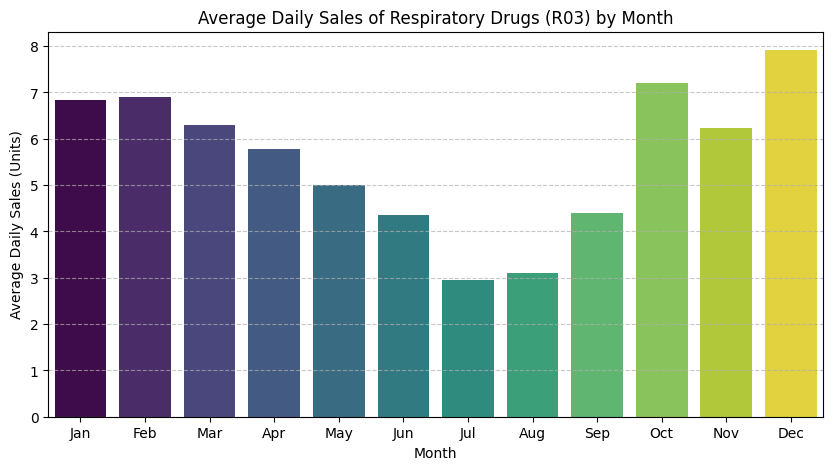

,Month,R03
11,12,7.916129
9,10,7.208589
1,2,6.896943
0,1,6.835980
2,3,6.290323
10,11,6.226667
3,4,5.771528
4,5,5.006944
8,9,4.402315
5,6,4.350000


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

monthly_r03 = df_sales.groupby('Month')['R03'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='Month', y='R03', data=monthly_r03, palette='viridis', hue='Month', legend=False)
plt.title('Average Daily Sales of Respiratory Drugs (R03) by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales (Units)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

display(monthly_r03.sort_values(by='R03', ascending=False))

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

yearly_sales = df_sales.groupby('Year')[atc_cols].sum()

In [11]:
yearly_sales

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Year,,,,,,,,
2014,1447.215000,1257.104312,1616.466500,9274.376875,4315.062500,272.625000,1255.000000,800.4875
2015,1895.620000,1496.603000,1608.630000,11923.225000,2965.000000,159.000000,1721.250000,983.0300
2016,2107.285000,1589.441000,1655.216667,13335.580000,3138.333333,207.000000,2137.000000,1065.0700
2017,1846.617083,1387.298333,1288.295833,9258.804833,2555.541667,180.333333,1893.614583,988.8600
2018,1786.930000,1389.656000,1123.800000,11230.925000,3266.200000,235.000000,2655.250000,1196.8000
2019,1517.270000,1084.516000,879.800000,7982.491000,2405.600000,196.000000,1946.708333,1073.5700


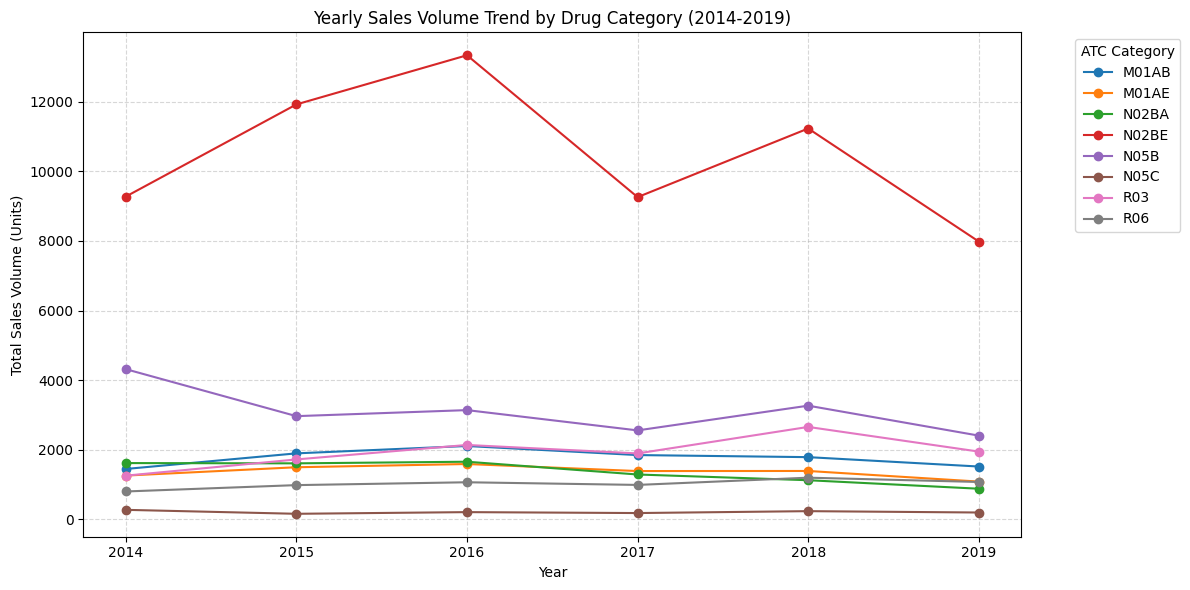

In [12]:
plt.figure(figsize=(12, 6))
for col in atc_cols:
    plt.plot(yearly_sales.index, yearly_sales[col], marker='o', label=col)

plt.title('Yearly Sales Volume Trend by Drug Category (2014-2019)')
plt.xlabel('Year')
plt.ylabel('Total Sales Volume (Units)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='ATC Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
